# CMZ Civet Behavior Classification — Phase 2
### Task 1 (Image-based Behavior Classification): CNN, Active vs Inactive

**Course:** Digital Image Processing — Chiang Mai University
**Team:** CMZ (Chiang Mai Zoo civet behavior project)

**What this notebook does**

1. Downloads the official labeled dataset (the "วิดิโอชะมดทำai" Drive folder named in the Phase 1 brief):
   `https://drive.google.com/drive/folders/1wHgqAzrEckiyO4wlrSPLZ-hcXGjzKRtd`
   — 3 behavior-sorted clip sets: **Eating (5 clips)**, **Locomotion (10 clips)**, **Resting (7 clips)** — 22 clips total.
2. Extracts frames from every clip and relabels them into two classes:
   - **Active** = Eating + Locomotion clips
   - **Inactive** = Resting clips
3. Fine-tunes a pretrained **MobileNetV2** CNN (transfer learning) to classify a frame as Active / Inactive.
4. Evaluates the model (confusion matrix, per-video active/inactive table, accuracy) and saves everything you need for the submission: trained model, results table, charts.

**Submission checklist this notebook fulfills:**
- [x] Train the model (dataset selected: the official labeled clips, not the raw unlabeled camera footage — see markdown note below)
- [x] Explain the AI/image model selected (see the write-up near the end)
- [x] Design and evaluate the output (active/inactive table + confusion matrix + accuracy)
- [ ] Push this notebook + results to GitHub (see the last section for a ready-to-use repo structure)

**Before running:** In Colab, go to `Runtime > Change runtime type` and select a **T4 GPU** (free tier). The whole notebook (download + frame extraction + training) should take well under 15 minutes on GPU.


## Why this dataset, not the raw camera footage

Two datasets were shared for this project:

1. **The official one** (named directly in the Phase 1 brief's "Dataset:" line): short, pre-trimmed clips already sorted into `Eating/`, `Locomotion/`, `Resting/` folders — real ground-truth labels, no guessing needed.
2. **Raw, unlabeled, full-day footage** from cameras 1–4 (several hundred MB per file, no behavior labels at all).

This notebook uses dataset (1). It's the one the course actually points to, it already has trustworthy labels, and it's small enough to train on in minutes instead of hours.


In [1]:
# 1. Install dependencies (Colab already has TensorFlow; this just adds the extras we need)
!pip install -q gdown opencv-python-headless scikit-learn seaborn


In [2]:
import os
import glob
import shutil
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the official labeled dataset

This pulls the whole `วิดิโอชะมดทำai` folder (Eating / Locomotion / Resting subfolders) straight from Drive.


In [3]:
FOLDER_ID = "1wHgqAzrEckiyO4wlrSPLZ-hcXGjzKRtd"
RAW_DIR = "cmz_raw"

if os.path.exists(RAW_DIR):
    shutil.rmtree(RAW_DIR)

!gdown --folder "https://drive.google.com/drive/folders/{FOLDER_ID}" -O {RAW_DIR} --quiet

# Sanity check: list what we got
for root, dirs, files in os.walk(RAW_DIR):
    level = root.replace(RAW_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root) or RAW_DIR}/  ({len(files)} files)")


cmz_raw/  (0 files)
  Locomotion/  (10 files)
  Eating/  (5 files)
  Resting/  (7 files)


**If `gdown --folder` fails** (Google occasionally rate-limits folder downloads): download the three subfolders manually from the Drive link as zip files, upload them to this Colab session (folder icon on the left → upload), and unzip them into `cmz_raw/Eating`, `cmz_raw/Locomotion`, `cmz_raw/Resting` — then skip straight to the next cell.


## 3. Extract frames and relabel into Active / Inactive

We sample evenly-spaced frames from every clip (this both turns 22 videos into a few hundred training images, and is a simple form of data augmentation by itself — slightly different frames of the same behavior).


In [4]:
ACTIVE_FOLDERS = ["Eating", "Locomotion"]
INACTIVE_FOLDERS = ["Resting"]
FRAMES_PER_CLIP = 25

FRAMES_DIR = "cmz_frames"
if os.path.exists(FRAMES_DIR):
    shutil.rmtree(FRAMES_DIR)
os.makedirs(os.path.join(FRAMES_DIR, "active"), exist_ok=True)
os.makedirs(os.path.join(FRAMES_DIR, "inactive"), exist_ok=True)


def extract_frames(video_path, out_dir, tag, n_frames=FRAMES_PER_CLIP):
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        return 0
    idxs = np.linspace(0, total - 1, min(n_frames, total)).astype(int)
    saved = 0
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, frame = cap.read()
        if not ok:
            continue
        out_path = os.path.join(out_dir, f"{tag}_f{int(i):05d}.jpg")
        cv2.imwrite(out_path, frame)
        saved += 1
    cap.release()
    return saved


def process_class(folder_names, label):
    out_dir = os.path.join(FRAMES_DIR, label)
    video_log = []
    for folder in folder_names:
        folder_path = os.path.join(RAW_DIR, folder)
        videos = sorted(glob.glob(os.path.join(folder_path, "*.mp4")) +
                         glob.glob(os.path.join(folder_path, "*.MP4")))
        for v in videos:
            # prefix with the source folder so same-named clips from different
            # folders (e.g. two files both called clip1.mp4) never collide
            tag = f"{folder}_{os.path.splitext(os.path.basename(v))[0]}"
            n = extract_frames(v, out_dir, tag)
            video_log.append({"source_folder": folder, "video": os.path.basename(v), "frames_extracted": n})
    return video_log

log_active = process_class(ACTIVE_FOLDERS, "active")
log_inactive = process_class(INACTIVE_FOLDERS, "inactive")

video_log_df = pd.DataFrame(log_active + log_inactive)
print(video_log_df)

n_active = len(glob.glob(os.path.join(FRAMES_DIR, "active", "*.jpg")))
n_inactive = len(glob.glob(os.path.join(FRAMES_DIR, "inactive", "*.jpg")))
print(f"\nTotal frames -> active: {n_active}, inactive: {n_inactive}")


   source_folder                  video  frames_extracted
0         Eating  25690518092326646.mp4                25
1         Eating  25690518092408866.mp4                25
2         Eating  25690519193422801.mp4                25
3         Eating  25690519193547292.mp4                25
4         Eating  25690519193808204.mp4                25
5     Locomotion  25690518090944462.mp4                25
6     Locomotion  25690518091012230.mp4                25
7     Locomotion  25690518091030781.mp4                25
8     Locomotion  25690518091047366.mp4                24
9     Locomotion  25690518091210873.mp4                25
10    Locomotion  25690518091711167.mp4                25
11    Locomotion  25690518091847591.mp4                25
12    Locomotion  25690518091918610.mp4                25
13    Locomotion  25690518091948946.mp4                25
14    Locomotion  25690520153014458.mp4                25
15       Resting  25690519194109670.mp4                25
16       Resti

## 4. Build train / validation datasets

**Important:** we split at the *clip* level, not the frame level. If we split frames
randomly, frames from the same clip (which look nearly identical to their neighbors)
could end up in both train and validation, which would inflate validation accuracy
without the model actually generalizing to new clips. So every frame from a given
video goes entirely into either train or validation, never both.


In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
class_names = ["active", "inactive"]  # label 0 = active, label 1 = inactive
label_to_idx = {name: i for i, name in enumerate(class_names)}

# Build a manifest of every extracted frame, tagged with the clip it came from
# (the tag is the "<folder>_<videoname>" prefix we used when saving each frame).
records = []
for label in class_names:
    for fp in sorted(glob.glob(os.path.join(FRAMES_DIR, label, "*.jpg"))):
        video_tag = os.path.basename(fp).rsplit("_f", 1)[0]
        records.append({"path": fp, "label": label, "video_tag": video_tag})
frames_df = pd.DataFrame(records)

# Split CLIPS (not frames) 80/20 into train/val, per class, with a fixed seed
rng = np.random.RandomState(SEED)
train_tags, val_tags = [], []
for label in class_names:
    tags = sorted(frames_df.loc[frames_df.label == label, "video_tag"].unique().tolist())
    rng.shuffle(tags)
    n_val = max(1, round(len(tags) * 0.2))
    val_tags.extend(tags[:n_val])
    train_tags.extend(tags[n_val:])

train_df = frames_df[frames_df.video_tag.isin(train_tags)].reset_index(drop=True)
val_df = frames_df[frames_df.video_tag.isin(val_tags)].reset_index(drop=True)

print(f"Train: {len(train_df)} frames from {len(train_tags)} clips -> {sorted(train_tags)}")
print(f"Val:   {len(val_df)} frames from {len(val_tags)} clips -> {sorted(val_tags)}")


def make_dataset(df, shuffle):
    paths = df["path"].values
    labels = df["label"].map(label_to_idx).values.astype("float32").reshape(-1, 1)

    def load_img(path, label):
        img = tf.io.read_file(path)
        img = tf.io.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_img, num_parallel_calls=AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(max(len(df), 1), seed=SEED)
    return ds.batch(BATCH_SIZE).cache().prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)  # order preserved, matches val_df row order


Train: 449 frames from 18 clips -> ['Eating_25690518092408866', 'Eating_25690519193422801', 'Eating_25690519193547292', 'Eating_25690519193808204', 'Locomotion_25690518090944462', 'Locomotion_25690518091012230', 'Locomotion_25690518091030781', 'Locomotion_25690518091047366', 'Locomotion_25690518091711167', 'Locomotion_25690518091918610', 'Locomotion_25690518091948946', 'Locomotion_25690520153014458', 'Resting_25690519194200758', 'Resting_25690519194418953', 'Resting_25690519194809256', 'Resting_25690519195143424', 'Resting_25690520152850102', 'Resting_25690520153258104']
Val:   100 frames from 4 clips -> ['Eating_25690518092326646', 'Locomotion_25690518091210873', 'Locomotion_25690518091847591', 'Resting_25690519194109670']


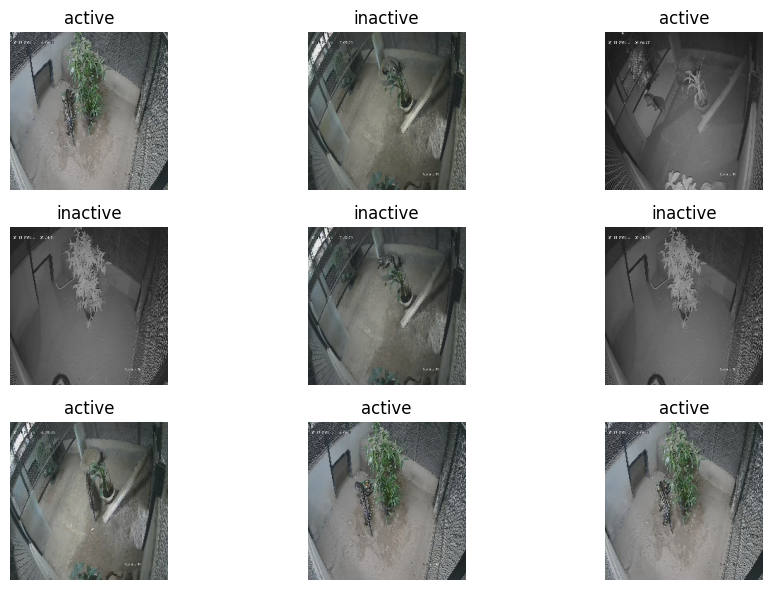

In [6]:
# Quick visual sanity check of a batch
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(np.clip(images[i].numpy(), 0, 255).astype("uint8"))
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")
plt.tight_layout()
plt.show()


## 5. Model: MobileNetV2 transfer learning

Data augmentation + preprocessing are built into the model itself, so the same model works correctly on raw images at inference time with no separate preprocessing script.


In [7]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
], name="augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False  # freeze for initial training

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs, name="cmz_behavior_classifier")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cmz_behavior_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Train (frozen base), then fine-tune


In [8]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=5, restore_best_weights=True
)

EPOCHS_HEAD = 15
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=[early_stop],
)


Epoch 1/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 20s 149ms/step - accuracy: 0.5367 - loss: 0.8246 - val_accuracy: 0.7200 - val_loss: 0.5365
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.6281 - loss: 0.7127 - val_accuracy: 0.7500 - val_loss: 0.4999
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.6013 - loss: 0.7167 - val_accuracy: 0.7500 - val_loss: 0.4666
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.6615 - loss: 0.6583 - val_accuracy: 0.7500 - val_loss: 0.4380
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.6860 - loss: 0.6387 - val_accuracy: 0.7500 - val_loss: 0.4171
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7060 - loss: 0.6181 - val_accuracy: 0.7500 - val_loss: 0.3980
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.7016 - loss: 0.5951 - val_accuracy: 0.7800 - val_loss: 0.3805
Epoch 8/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.7038 - loss: 0.5708 - val_accuracy: 0.7600 -

In [9]:
# Fine-tune: unfreeze the top layers of the base model and train a little more with a low LR
base_model.trainable = True
FINE_TUNE_AT = len(base_model.layers) - 30  # unfreeze roughly the last 30 layers
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

EPOCHS_FINE_TUNE = 8
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=[early_stop],
)


Epoch 1/8
29/29 ━━━━━━━━━━━━━━━━━━━━ 14s 129ms/step - accuracy: 0.7060 - loss: 0.5745 - val_accuracy: 0.9400 - val_loss: 0.2681
Epoch 2/8
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.8018 - loss: 0.4725 - val_accuracy: 0.9800 - val_loss: 0.2146
Epoch 3/8
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8575 - loss: 0.4088 - val_accuracy: 0.9800 - val_loss: 0.1832
Epoch 4/8
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8486 - loss: 0.3710 - val_accuracy: 0.9800 - val_loss: 0.1600
Epoch 5/8
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8797 - loss: 0.3368 - val_accuracy: 0.9800 - val_loss: 0.1428
Epoch 6/8
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8463 - loss: 0.3204 - val_accuracy: 0.9800 - val_loss: 0.1335
Epoch 7/8
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8753 - loss: 0.3168 - val_accuracy: 0.9800 - val_loss: 0.1300


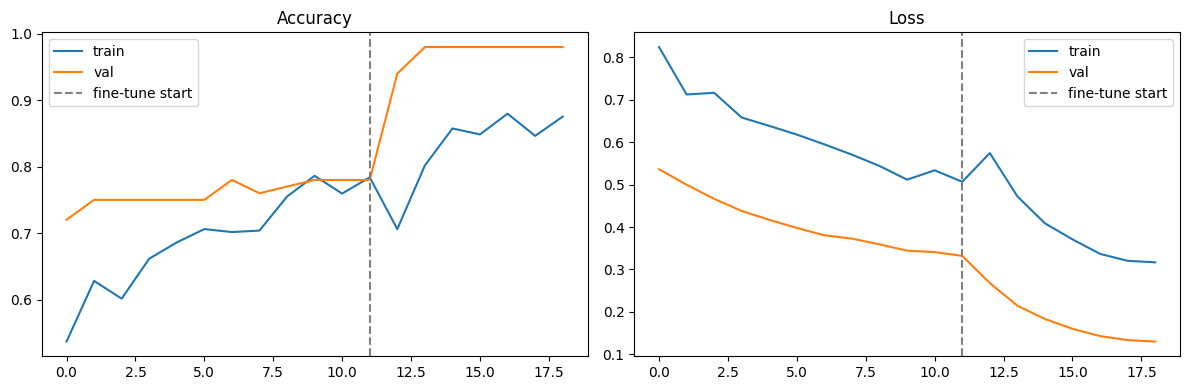

In [10]:
# Combined training curves
acc = history.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_fine.history["val_accuracy"]
loss = history.history["loss"] + history_fine.history["loss"]
val_loss = history.history["val_loss"] + history_fine.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(acc, label="train")
axes[0].plot(val_acc, label="val")
axes[0].axvline(len(history.history["accuracy"]) - 1, color="gray", linestyle="--", label="fine-tune start")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(loss, label="train")
axes[1].plot(val_loss, label="val")
axes[1].axvline(len(history.history["loss"]) - 1, color="gray", linestyle="--", label="fine-tune start")
axes[1].set_title("Loss")
axes[1].legend()
plt.tight_layout()
plt.show()


## 7. Evaluate: confusion matrix, classification report, active/inactive table


Confusion matrix (rows=true, cols=predicted), classes: ['active', 'inactive']
[[75  0]
 [ 2 23]]

              precision    recall  f1-score   support

      active       0.97      1.00      0.99        75
    inactive       1.00      0.92      0.96        25

    accuracy                           0.98       100
   macro avg       0.99      0.96      0.97       100
weighted avg       0.98      0.98      0.98       100



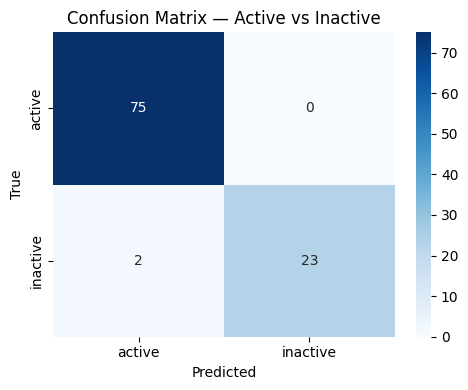

In [11]:
# val_ds was built with shuffle=False, so batches come out in the same order
# as val_df's rows - we can match predictions back to filenames directly.
y_true = val_df["label"].map(label_to_idx).values.astype(int)
y_prob = model.predict(val_ds, verbose=0).flatten()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
print("Confusion matrix (rows=true, cols=predicted), classes:", class_names)
print(cm)
print()
print(classification_report(y_true, y_pred, target_names=class_names))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix — Active vs Inactive")
plt.tight_layout()
plt.show()


In [12]:
# Per-frame active/inactive results table (the "design and evaluate the output" deliverable)
results_df = pd.DataFrame({
    "file": [os.path.basename(p) for p in val_df["path"]],
    "video_clip": val_df["video_tag"].values,
    "true_label": [class_names[i] for i in y_true],
    "predicted_label": [class_names[i] for i in y_pred],
    "confidence": [p if pred == 1 else 1 - p for p, pred in zip(y_prob, y_pred)],
})
results_df["correct"] = results_df["true_label"] == results_df["predicted_label"]

results_df.to_csv("results_table.csv", index=False)
print(f"Frame-level validation accuracy: {results_df['correct'].mean():.2%}")
results_df.head(15)


Frame-level validation accuracy: 98.00%


,file,video_clip,true_label,predicted_label,confidence,correct
0,Eating_25690518092326646_f00000.jpg,Eating_25690518092326646,active,active,0.920437,True
1,Eating_25690518092326646_f00050.jpg,Eating_25690518092326646,active,active,0.872975,True
2,Eating_25690518092326646_f00100.jpg,Eating_25690518092326646,active,active,0.772878,True
3,Eating_25690518092326646_f00151.jpg,Eating_25690518092326646,active,active,0.902782,True
4,Eating_25690518092326646_f00201.jpg,Eating_25690518092326646,active,active,0.760759,True
5,Eating_25690518092326646_f00251.jpg,Eating_25690518092326646,active,active,0.900330,True
6,Eating_25690518092326646_f00302.jpg,Eating_25690518092326646,active,active,0.847876,True
7,Eating_25690518092326646_f00352.jpg,Eating_25690518092326646,active,active,0.870907,True
8,Eating_25690518092326646_f00403.jpg,Eating_25690518092326646,active,active,0.732061,True
9,Eating_25690518092326646_f00453.jpg,Eating_25690518092326646,active,active,0.908012,True


In [13]:
# Per-CLIP active/inactive table (majority vote across that clip's frames) -
# this is the cleaner table to put on a presentation slide: one row per video.
video_level = (
    results_df.groupby(["video_clip", "true_label"])
    .agg(
        predicted_label=("predicted_label", lambda s: s.value_counts().idxmax()),
        mean_confidence=("confidence", "mean"),
        frames_evaluated=("predicted_label", "count"),
    )
    .reset_index()
)
video_level["correct"] = video_level["true_label"] == video_level["predicted_label"]
video_level.to_csv("video_level_table.csv", index=False)
print(f"Clip-level validation accuracy: {video_level['correct'].mean():.2%} "
      f"({video_level['correct'].sum()}/{len(video_level)} held-out clips)")
video_level


Clip-level validation accuracy: 100.00% (4/4 held-out clips)


,video_clip,true_label,predicted_label,mean_confidence,frames_evaluated,correct
0,Eating_25690518092326646,active,active,0.872379,25,True
1,Locomotion_25690518091210873,active,active,0.885323,25,True
2,Locomotion_25690518091847591,active,active,0.914772,25,True
3,Resting_25690519194109670,inactive,inactive,0.636964,25,True


/tmp/ipykernel_1903/2780147075.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=summary.index, y=summary.values, palette=["#4C9F70", "#C96567"])


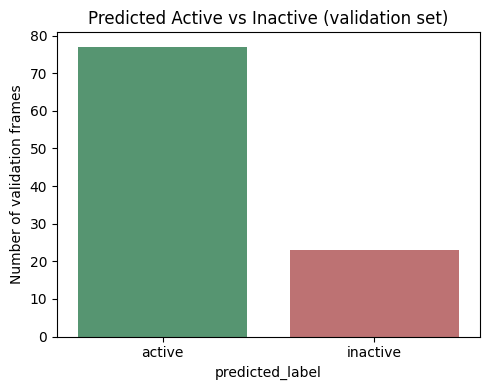

,count
predicted_label,
active,77
inactive,23


In [14]:
# Summary bar chart: predicted active vs inactive counts
summary = results_df["predicted_label"].value_counts().reindex(class_names, fill_value=0)
plt.figure(figsize=(5, 4))
sns.barplot(x=summary.index, y=summary.values, palette=["#4C9F70", "#C96567"])
plt.ylabel("Number of validation frames")
plt.title("Predicted Active vs Inactive (validation set)")
plt.tight_layout()
plt.show()

summary


## 8. Save the trained model


In [15]:
model.save("cmz_behavior_classifier.keras")
print("Saved model to cmz_behavior_classifier.keras")

# Optional: save to your own Google Drive instead of just the Colab session
# from google.colab import drive
# drive.mount('/content/drive')
# model.save('/content/drive/MyDrive/cmz_behavior_classifier.keras')
# results_df.to_csv('/content/drive/MyDrive/results_table.csv', index=False)


Saved model to cmz_behavior_classifier.keras


## 9. The AI/image model we selected — explanation

**Task:** Task 1 from the course brief — Image-based Behavior Classification (`Image Dataset → Labeling → CNN → Behavior Classification`), simplified from the original 4 behavior labels to a binary **Active vs Inactive** classification, matching what was asked for the Phase 2 submission.

**Model: MobileNetV2, used via transfer learning**

- **Why a CNN at all:** convolutional layers learn spatial features (edges, textures, body posture/shape) directly from pixels, which is exactly what distinguishes an eating/moving civet from a resting one — no hand-designed feature extraction needed, unlike the classical Chapter 2–7 pipeline (gamma correction, thresholding, morphology) used in Phase 1.
- **Why MobileNetV2 specifically:** it uses depthwise-separable convolutions, which give it far fewer parameters and FLOPs than a standard CNN of similar depth (e.g. VGG or a vanilla ResNet). That means it trains fast on a free Colab GPU (minutes, not hours) and does not overfit as quickly on a small dataset — both important given our dataset is only 22 source clips.
- **Why transfer learning instead of training from scratch:** MobileNetV2 is pretrained on ImageNet (1.4M images, 1000 classes). Its early/middle layers already encode general-purpose visual features (edges, textures, shapes) that transfer well to a new, unrelated image domain. We freeze those layers, train only a small classification head on our data first, then unfreeze the last ~30 layers for a brief fine-tuning pass at a low learning rate. Training a full CNN from scratch on ~400–500 frames (after frame extraction) would badly overfit.
- **Why frame sampling from video rather than video-level models:** the brief's Task 1 pipeline is explicitly image-based (`Image Dataset → Labeling → CNN`), not video-based (that's Task 2/YOLO or Task 3/pose territory). Sampling evenly-spaced frames turns each clip into many labeled training images while keeping the model and pipeline simple enough to finish and explain clearly under the deadline.
- **Why binary Active/Inactive instead of 4-way (Walking/Eating/Resting/Climbing):** the real labeled dataset only provides 3 categories (Eating, Locomotion, Resting — no separate Climbing clips exist), and the Phase 2 submission instructions explicitly ask for an "active and inactive table or visualization." Mapping Eating + Locomotion → Active and Resting → Inactive uses the real labels as-is, with no guessing, and directly produces the deliverable that's asked for.


## 10. Pushing this to GitHub

Suggested repo layout:

```
cmz-phase2-behavior-classification/
├── README.md
├── CMZ_Phase2_Behavior_Classification.ipynb   (this notebook)
├── results_table.csv                           (generated above)
├── cmz_behavior_classifier.keras                (generated above — optional, can be large)
└── figures/
    ├── confusion_matrix.png
    └── training_curves.png
```

From Colab, the fastest path:

1. `File > Download > Download .ipynb` to get this notebook onto your computer (or `File > Save a copy in GitHub` directly from the Colab menu, if you sign in with GitHub).
2. Also download `results_table.csv` and `cmz_behavior_classifier.keras` from the Colab file browser (left sidebar → folder icon → right-click → Download).
3. On your computer:
   ```bash
   git init cmz-phase2-behavior-classification
   cd cmz-phase2-behavior-classification
   # copy in the downloaded files
   git add .
   git commit -m "Phase 2: CNN-based active/inactive behavior classification"
   git branch -M main
   git remote add origin <your-empty-github-repo-url>
   git push -u origin main
   ```
4. Paste the resulting GitHub URL into your submission.
